[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/diffusion/diffusion.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Diffusion Models on MNIST

Tutorial for training a denoising diffusion model (DDPM) that generates MNIST-like handwritten digits.

A diffusion model has two processes:

- The **forward process** gradually adds Gaussian noise to an image until it becomes pure noise.
- The **reverse process** starts from noise and removes a little of it at each step.

What we will do:

1. Build the forward process and its **noise scheduler**, and check that we can jump to any step in one go.
2. Train a U-Net to **predict the noise** that was added ($L_\text{simple}$).
3. Generate step by step, and look at what the network "sees" at each step and at the small amount of fresh noise added in each one.
4. Generate much faster with **DDIM**.
5. Start from a real image instead of pure noise.
6. Tell the model which digit we want, with **classifier-free guidance** (the same idea that steers Stable Diffusion with a prompt).
7. See what goes wrong when the scheduler does not reach pure noise.

The companion notebook `stable_diffusion.ipynb` opens Stable Diffusion piece by piece.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything()

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

`num_timesteps`, `beta_start` and `beta_end` are the values of the DDPM paper (Ho et al., 2020): $T = 1000$ steps, with $\beta_t$ growing linearly from $10^{-4}$ to $0.02$. They must be chosen together: section 18 shows what happens if we keep these $\beta$ but use only 100 steps.

`LOAD_CHECKPOINTS = True` loads a model that is already trained and saved in `output_dir` instead of training it again.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "diffusion" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "diffusion" / "outputs" / "mnist_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
base_channels = 64
time_embedding_dim = 128
num_timesteps = 1000   # T
beta_start = 1e-4
beta_end = 2e-2
epochs = 30
learning_rate = 2e-4

sample_every_epochs = 5
LOAD_CHECKPOINTS = True

## 3. Load MNIST

Diffusion models work with centered values: we take MNIST from $[0, 1]$ to $[-1, 1]$, the same range as the noise, and back to $[0, 1]$ only to display it.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),                          # [0, 1]
    transforms.Normalize(mean=(0.5,), std=(0.5,)),  # [-1, 1]
])

train_dataset = datasets.MNIST(root=data_dir, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root=data_dir, train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2,
                         pin_memory=torch.cuda.is_available())

test_images = torch.cat([images for images, _ in test_loader]).to(device)
test_labels = torch.cat([labels for _, labels in test_loader]).to(device)

len(train_dataset), len(test_dataset)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_wo

(60000, 10000)

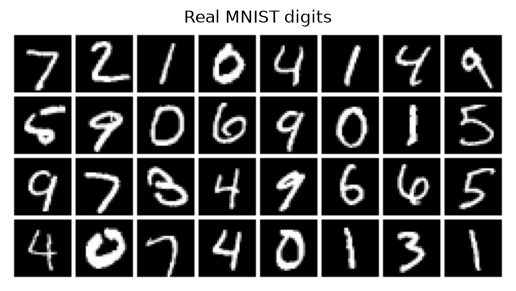

In [5]:
def denormalize(images):
    return (images + 1) / 2


def show_image_grid(images, title=None, nrow=8, size=0.8):
    images = denormalize(images.detach().float().cpu()).clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2, pad_value=1.0)
    rows = math.ceil(images.size(0) / nrow)
    plt.figure(figsize=(size * nrow, size * rows + (0.4 if title else 0)))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def show_rows(rows, row_titles=None, column_titles=None, title=None, size=0.9):
    """Shows a table of images: `rows` is a list of tensors with the same number of images each."""
    n_rows, n_columns = len(rows), rows[0].size(0)
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(size * n_columns + 1.2, size * n_rows + 0.4), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(n_columns):
            ax = axes[r, c]
            ax.imshow(denormalize(row[c].detach().float().cpu()).clamp(0, 1).squeeze(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0 and column_titles:
                ax.set_title(column_titles[c], fontsize=8)
            if c == 0 and row_titles:
                ax.set_ylabel(row_titles[r], fontsize=8, rotation=0, ha="right", va="center")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_image_grid(test_images[:32], title="Real MNIST digits")

## 4. The Forward Process and the Noise Scheduler

Each forward step adds a little Gaussian noise:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\big(\sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big)$$

How much noise each step adds, $\beta_t$, is decided by the **noise scheduler**. With $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \prod_{s \le t} \alpha_s$ (the product of all the steps so far), we can also jump from $x_0$ to any $x_t$ in one go:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

In code, timesteps go from `0` to `T - 1`: index `t` is the image after `t + 1` noising steps, so `x_T` is index `T - 1`.

In [6]:
def linear_betas(num_timesteps, beta_start, beta_end):
    return torch.linspace(beta_start, beta_end, num_timesteps)


def make_schedule(betas):
    betas = betas.to(device)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    alpha_bars_previous = F.pad(alpha_bars[:-1], (1, 0), value=1.0)
    return {
        "num_timesteps": len(betas),
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
        "alpha_bars_previous": alpha_bars_previous,
        # Variance of the true reverse step q(x_{t-1} | x_t, x_0): the fresh noise we add when sampling
        "posterior_variance": betas * (1.0 - alpha_bars_previous) / (1.0 - alpha_bars),
    }


schedule = make_schedule(linear_betas(num_timesteps, beta_start, beta_end))


def extract(values, timesteps, x_shape):
    """Picks values[t] for each image and reshapes it so it multiplies a batch of images."""
    return values.gather(0, timesteps).reshape(timesteps.shape[0], *((1,) * (len(x_shape) - 1)))


def q_sample(x_start, timesteps, noise=None, schedule=schedule):
    """Jumps from x_0 to x_t in one go: x_t = sqrt(alpha_bar_t) x_0 + sqrt(1 - alpha_bar_t) epsilon."""
    if noise is None:
        noise = torch.randn_like(x_start)
    alpha_bar_t = extract(schedule["alpha_bars"], timesteps, x_start.shape)
    return torch.sqrt(alpha_bar_t) * x_start + torch.sqrt(1.0 - alpha_bar_t) * noise

The two weights of the jump formula: the image weighs almost 1 at the beginning and almost 0 at the end.

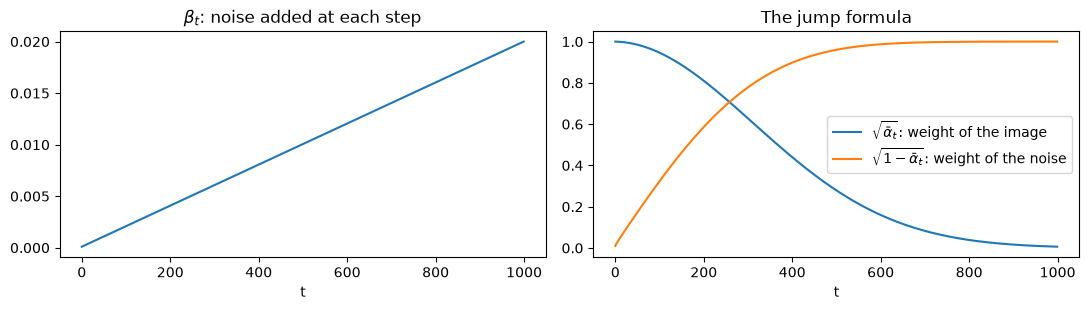

At the last step, the image weighs 0.0064 and the noise 1.0000


In [7]:
def plot_schedule(schedule, label=None, axes=None):
    alpha_bars = schedule["alpha_bars"].cpu().numpy()
    t = np.arange(len(alpha_bars))
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot(t, schedule["betas"].cpu().numpy(), label=label)
    axes[0].set_title(r"$\beta_t$: noise added at each step")
    axes[1].plot(t, np.sqrt(alpha_bars), label=r"$\sqrt{\bar\alpha_t}$: weight of the image")
    axes[1].plot(t, np.sqrt(1 - alpha_bars), label=r"$\sqrt{1-\bar\alpha_t}$: weight of the noise")
    axes[1].set_title("The jump formula")
    for ax in axes:
        ax.set_xlabel("t")
    axes[1].legend()
    return axes


plot_schedule(schedule)
plt.tight_layout()
plt.show()

alpha_bar_T = schedule["alpha_bars"][-1]
print(f"At the last step, the image weighs {alpha_bar_T.sqrt():.4f} and the noise {(1 - alpha_bar_T).sqrt():.4f}")

## 5. Step by Step, or in One Jump

The forward process is defined step by step, but because every step adds Gaussian noise, all of them collapse into the single jump formula. Let's check it: we noise 1000 test digits by applying $q(x_t \mid x_{t-1})$ again and again, and compare them with the ones we get by jumping directly. They will not be the same images (the noise is random), but they should have the same statistics: how spread the pixels are and how much of the original digit is left.

                               step by step                       one jump
       after      pixel std  corr. with x_0       pixel std  corr. with x_0
   100 steps          0.650           0.858           0.650           0.857
   250 steps          0.814           0.518           0.813           0.519
   500 steps          0.974           0.169           0.974           0.169
  1000 steps          1.001           0.006           1.001           0.003


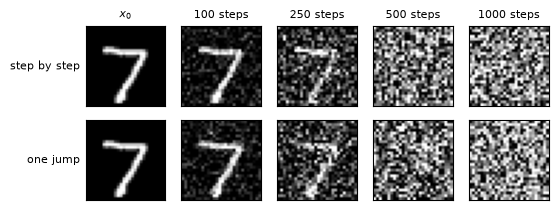

In [8]:
@torch.no_grad()
def q_step(x_previous, t, schedule=schedule):
    """One forward step: x_t = sqrt(1 - beta_t) x_{t-1} + sqrt(beta_t) epsilon."""
    beta_t = schedule["betas"][t]
    return torch.sqrt(1.0 - beta_t) * x_previous + torch.sqrt(beta_t) * torch.randn_like(x_previous)


def correlation_with(x, reference):
    """Average correlation between each image and its reference: 1 = the same digit, 0 = nothing left of it."""
    a = (x - x.mean((1, 2, 3), keepdim=True)).flatten(1)
    b = (reference - reference.mean((1, 2, 3), keepdim=True)).flatten(1)
    return ((a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1))).mean().item()


seed_everything()
x_0 = test_images[:1000]
checkpoints = [99, 249, 499, num_timesteps - 1]

x = x_0.clone()
step_by_step = {}
for t in range(num_timesteps):
    x = q_step(x, t)
    if t in checkpoints:
        step_by_step[t] = x.clone()

one_jump = {t: q_sample(x_0, torch.full((len(x_0),), t, device=device)) for t in checkpoints}

print(f"{'':>12} {'step by step':>30} {'one jump':>30}")
print(f"{'after':>12} {'pixel std':>14} {'corr. with x_0':>15} {'pixel std':>15} {'corr. with x_0':>15}")
for t in checkpoints:
    a, b = step_by_step[t], one_jump[t]
    print(f"{t + 1:>6} steps {a.std().item():>14.3f} {correlation_with(a, x_0):>15.3f} "
          f"{b.std().item():>15.3f} {correlation_with(b, x_0):>15.3f}")

show_rows(
    [torch.cat([x_0[:1]] + [step_by_step[t][:1] for t in checkpoints]),
     torch.cat([x_0[:1]] + [one_jump[t][:1] for t in checkpoints])],
    row_titles=["step by step", "one jump"],
    column_titles=["$x_0$"] + [f"{t + 1} steps" for t in checkpoints],
)

At the end, $x_T$ should be indistinguishable from pure Gaussian noise $\mathcal{N}(0, I)$, because that is where generation will start.

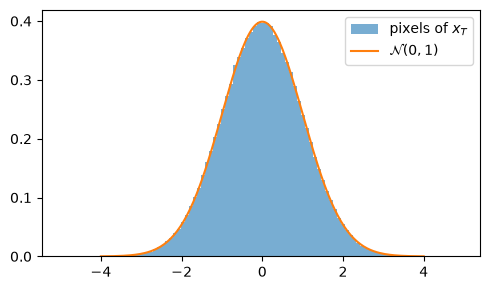

x_T: mean -0.004, std 1.001, correlation with x_0 0.003


In [9]:
x_T = one_jump[num_timesteps - 1]
values = np.linspace(-4, 4, 200)
plt.figure(figsize=(5, 3))
plt.hist(x_T.flatten().cpu().numpy(), bins=100, density=True, alpha=0.6, label=r"pixels of $x_T$")
plt.plot(values, np.exp(-values ** 2 / 2) / np.sqrt(2 * np.pi), label=r"$\mathcal{N}(0, 1)$")
plt.legend()
plt.tight_layout()
plt.show()
print(f"x_T: mean {x_T.mean().item():.3f}, std {x_T.std().item():.3f}, correlation with x_0 {correlation_with(x_T, x_0):.3f}")

## 6. Visualize the Forward Process

The same digits at several steps, each with its own noise. The fine details go first; the overall shape lasts longer.

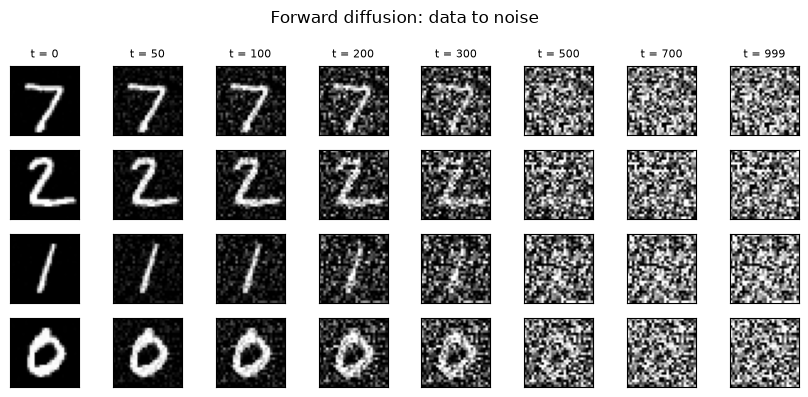

In [10]:
forward_timesteps = [0, 50, 100, 200, 300, 500, 700, num_timesteps - 1]
seed_everything()
digits = test_images[:4]
noise = torch.randn_like(digits)
show_rows(
    [torch.cat([q_sample(digit[None], torch.tensor([t], device=device), noise=eps[None]) for t in forward_timesteps])
     for digit, eps in zip(digits, noise)],
    column_titles=[f"t = {t}" for t in forward_timesteps],
    title="Forward diffusion: data to noise",
)

## 7. Time Embeddings

The same network removes noise at every step, so it must know which step it is looking at: almost pure noise and an almost clean digit need very different corrections. We encode `t` with sinusoidal features and pass them through a small MLP before injecting them into the convolutional blocks.

In [11]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2
        frequencies = torch.exp(
            torch.arange(half_dim, device=timesteps.device)
            * (-math.log(10000) / (half_dim - 1))
        )
        angles = timesteps[:, None] * frequencies[None, :]
        embedding = torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1)

        if self.embedding_dim % 2 == 1:
            embedding = F.pad(embedding, (0, 1))

        return embedding

## 8. Define the Denoising U-Net

The network receives a noisy image $x_t$ and its step $t$, and predicts the noise $\epsilon$ that was added: $\epsilon_\theta(x_t, t)$.

It is a compact U-Net: the encoder lowers the resolution from `28 x 28` to `14 x 14` to `7 x 7`, the middle block works at low resolution, and the decoder upsamples using skip connections from the encoder. The output has the same size as the input, because it is noise for that image. `extra_embedding` is unused for now: section 17 uses it to tell the network which digit to draw.

In [12]:
def num_groups(channels):
    return 8 if channels % 8 == 0 else 1


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(num_groups(out_channels), out_channels)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(num_groups(out_channels), out_channels)
        self.residual = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, time_embedding):
        h = self.conv1(x)
        h = self.norm1(h)
        h = h + self.time_projection(time_embedding)[:, :, None, None]
        h = F.silu(h)
        h = self.conv2(h)
        h = self.norm2(h)
        h = F.silu(h)
        return h + self.residual(x)


class DenoisingUNet(nn.Module):
    def __init__(self, image_channels=1, base_channels=64, time_dim=128, num_timesteps=1000):
        super().__init__()
        self.num_timesteps = num_timesteps
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.initial = nn.Conv2d(image_channels, base_channels, kernel_size=3, padding=1)

        self.down_block1 = ResidualBlock(base_channels, base_channels, time_dim)
        self.downsample1 = nn.Conv2d(base_channels, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.down_block2 = ResidualBlock(base_channels * 2, base_channels * 2, time_dim)
        self.downsample2 = nn.Conv2d(base_channels * 2, base_channels * 4, kernel_size=4, stride=2, padding=1)

        self.middle = ResidualBlock(base_channels * 4, base_channels * 4, time_dim)

        self.upsample2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.up_block2 = ResidualBlock(base_channels * 4, base_channels * 2, time_dim)
        self.upsample1 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)
        self.up_block1 = ResidualBlock(base_channels * 2, base_channels, time_dim)

        self.output = nn.Sequential(
            nn.GroupNorm(num_groups(base_channels), base_channels),
            nn.SiLU(),
            nn.Conv2d(base_channels, image_channels, kernel_size=3, padding=1),
        )

    def forward(self, x, timesteps, extra_embedding=None):
        scaled_timesteps = timesteps.float() / (self.num_timesteps - 1)
        time_embedding = self.time_mlp(scaled_timesteps)
        if extra_embedding is not None:
            time_embedding = time_embedding + extra_embedding

        x = self.initial(x)
        skip1 = self.down_block1(x, time_embedding)
        x = self.downsample1(skip1)
        skip2 = self.down_block2(x, time_embedding)
        x = self.downsample2(skip2)

        x = self.middle(x, time_embedding)

        x = self.upsample2(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.up_block2(x, time_embedding)
        x = self.upsample1(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.up_block1(x, time_embedding)

        return self.output(x)

## 9. The Training Loss: Predict the Noise

Training is a supervised problem: we added the noise, so we know the right answer. For each image of the batch:

1. Pick a random step $t$.
2. Sample Gaussian noise $\epsilon$.
3. Build $x_t$ in one jump (section 4).
4. Ask the network for $\epsilon_\theta(x_t, t)$ and measure the squared error.

This is $L_\text{simple} = \mathbb{E}_{x_0, \epsilon, t}\big[\lVert \epsilon - \epsilon_\theta(x_t, t) \rVert^2\big]$, the loss of the DDPM paper: the ELBO split into one term per step, without the weights of each term.

In [13]:
def diffusion_loss(model, images, schedule=schedule):
    t = torch.randint(0, schedule["num_timesteps"], (images.size(0),), device=device)  # a random step per image
    noise = torch.randn_like(images)                                                    # epsilon
    noisy_images = q_sample(images, t, noise=noise, schedule=schedule)                  # x_t, in one jump
    predicted_noise = model(noisy_images, t)                                            # epsilon_theta(x_t, t)
    return F.mse_loss(predicted_noise, noise)                                           # L_simple

In [14]:
def run_epoch(model, optimizer, loss_fn, data_loader, train=True):
    model.train(train)
    total_loss, total_images = 0.0, 0
    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)
        with torch.set_grad_enabled(train):
            loss = loss_fn(model, images, labels)
        if train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)
    return total_loss / total_images


def train(model, loss_fn, name, epochs=epochs, show_samples=None):
    """Trains `model` with `loss_fn(model, images, labels)`, or loads it if output_dir/<name>.pt already exists."""
    checkpoint_path = output_dir / f"{name}.pt"
    if LOAD_CHECKPOINTS and checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state_dict"])
        print(f"Loaded {checkpoint_path.name}, trained for {len(checkpoint['history'])} epochs")
        return checkpoint["history"]

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_loss = run_epoch(model, optimizer, loss_fn, train_loader, train=True)
        test_loss = run_epoch(model, optimizer, loss_fn, test_loader, train=False)
        history.append({"epoch": epoch, "train_loss": train_loss, "test_loss": test_loss})
        print(f"Epoch {epoch:03d}/{epochs:03d} | train loss: {train_loss:.4f} | test loss: {test_loss:.4f} | "
              f"{time.perf_counter() - start:.0f} s")
        if show_samples is not None and (epoch % sample_every_epochs == 0 or epoch == epochs):
            show_samples(epoch)
        torch.save({"model_state_dict": model.state_dict(), "history": history}, checkpoint_path)
    return history

## 10. Generating: the Reverse Step

To generate, we start from pure noise $x_T \sim \mathcal{N}(0, I)$ and go back one step at a time. In each step the network predicts the noise in the current image, and we:

1. **Remove part of the predicted noise.** This is the mean of the reverse step:
$$\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t)\Big)$$
2. **Add a little fresh noise**, with the variance of the true reverse step $q(x_{t-1} \mid x_t, x_0)$ (all steps except the last one):
$$x_{t-1} = \mu_\theta(x_t, t) + \sigma_t\, z, \qquad z \sim \mathcal{N}(0, I)$$

The reverse step is a Gaussian, so to follow it we have to *sample* from it, not just take its mean. Section 14 shows what happens if we skip the fresh noise.

In [15]:
@torch.no_grad()
def p_sample(model, x, timestep, add_noise=True, schedule=schedule):
    """One reverse step, from x_t to x_{t-1}."""
    t = torch.full((x.size(0),), timestep, device=device, dtype=torch.long)
    beta_t = extract(schedule["betas"], t, x.shape)
    alpha_t = extract(schedule["alphas"], t, x.shape)
    alpha_bar_t = extract(schedule["alpha_bars"], t, x.shape)

    predicted_noise = model(x, t)
    mean = (x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * predicted_noise) / torch.sqrt(alpha_t)

    if timestep == 0 or not add_noise:
        return mean
    variance = extract(schedule["posterior_variance"], t, x.shape)
    return mean + torch.sqrt(variance) * torch.randn_like(x)


@torch.no_grad()
def sample(model, num_samples=64, x_T=None, add_noise=True, schedule=schedule):
    """Generates images with the full reverse process (DDPM), from pure noise or from a given x_T."""
    model.eval()
    if x_T is None:
        x_T = torch.randn(num_samples, image_channels, image_size, image_size, device=device)
    x = x_T.clone()
    for timestep in reversed(range(schedule["num_timesteps"])):
        x = p_sample(model, x, timestep, add_noise=add_noise, schedule=schedule)
    return x.clamp(-1, 1)

## 11. Train the Diffusion Model

The loss measures how well the network predicts the noise. A lower loss usually means it is learning, but the samples are the real check: section 18 shows a model whose loss goes down normally and still generates scribbles.

3,574,465 parameters
Epoch 001/030 | train loss: 0.0722 | test loss: 0.0416 | 18 s
Epoch 002/030 | train loss: 0.0361 | test loss: 0.0330 | 14 s
Epoch 003/030 | train loss: 0.0313 | test loss: 0.0292 | 14 s
Epoch 004/030 | train loss: 0.0289 | test loss: 0.0280 | 14 s
Epoch 005/030 | train loss: 0.0273 | test loss: 0.0262 | 14 s


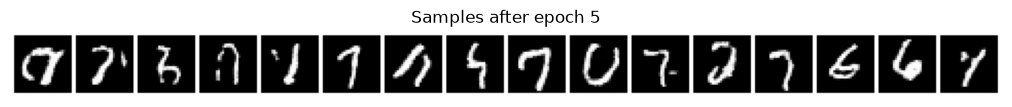

Epoch 006/030 | train loss: 0.0261 | test loss: 0.0264 | 15 s
Epoch 007/030 | train loss: 0.0261 | test loss: 0.0255 | 14 s
Epoch 008/030 | train loss: 0.0249 | test loss: 0.0247 | 15 s
Epoch 009/030 | train loss: 0.0245 | test loss: 0.0239 | 14 s
Epoch 010/030 | train loss: 0.0246 | test loss: 0.0251 | 15 s


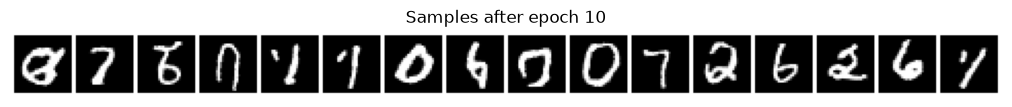

Epoch 011/030 | train loss: 0.0240 | test loss: 0.0251 | 14 s
Epoch 012/030 | train loss: 0.0241 | test loss: 0.0239 | 15 s
Epoch 013/030 | train loss: 0.0234 | test loss: 0.0233 | 14 s
Epoch 014/030 | train loss: 0.0233 | test loss: 0.0230 | 15 s
Epoch 015/030 | train loss: 0.0235 | test loss: 0.0241 | 14 s


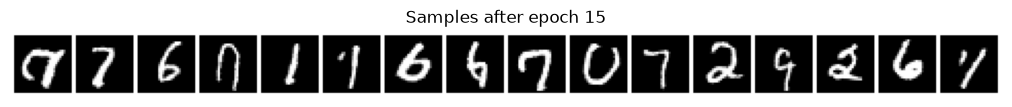

Epoch 016/030 | train loss: 0.0230 | test loss: 0.0238 | 15 s
Epoch 017/030 | train loss: 0.0232 | test loss: 0.0231 | 14 s
Epoch 018/030 | train loss: 0.0226 | test loss: 0.0235 | 15 s
Epoch 019/030 | train loss: 0.0225 | test loss: 0.0227 | 14 s
Epoch 020/030 | train loss: 0.0227 | test loss: 0.0237 | 15 s


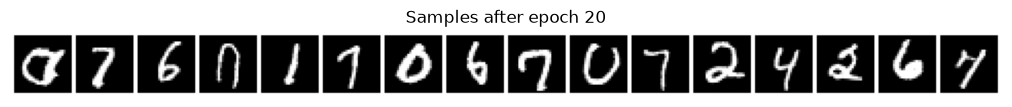

Epoch 021/030 | train loss: 0.0223 | test loss: 0.0233 | 14 s
Epoch 022/030 | train loss: 0.0225 | test loss: 0.0227 | 14 s
Epoch 023/030 | train loss: 0.0220 | test loss: 0.0233 | 14 s
Epoch 024/030 | train loss: 0.0218 | test loss: 0.0224 | 14 s
Epoch 025/030 | train loss: 0.0221 | test loss: 0.0240 | 14 s


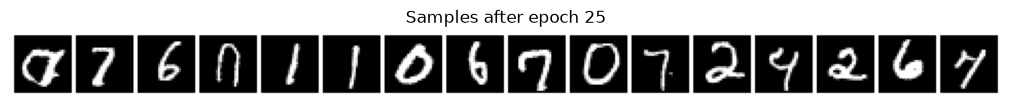

Epoch 026/030 | train loss: 0.0218 | test loss: 0.0236 | 14 s
Epoch 027/030 | train loss: 0.0219 | test loss: 0.0228 | 15 s
Epoch 028/030 | train loss: 0.0214 | test loss: 0.0227 | 14 s
Epoch 029/030 | train loss: 0.0213 | test loss: 0.0225 | 15 s
Epoch 030/030 | train loss: 0.0215 | test loss: 0.0237 | 14 s


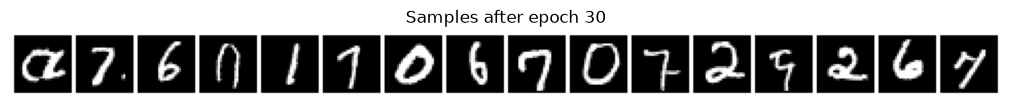

In [16]:
denoiser = DenoisingUNet(
    image_channels=image_channels,
    base_channels=base_channels,
    time_dim=time_embedding_dim,
    num_timesteps=num_timesteps,
).to(device)
print(f"{sum(p.numel() for p in denoiser.parameters()):,} parameters")


def show_samples_during_training(epoch):
    seed_everything(0)
    show_image_grid(sample(denoiser, 16), title=f"Samples after epoch {epoch}", nrow=16)


history = train(denoiser, lambda model, images, labels: diffusion_loss(model, images), "ddpm",
                show_samples=show_samples_during_training)

## 12. Training Curves

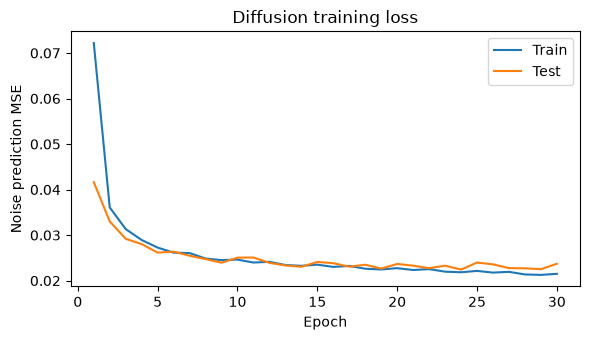

In [17]:
plt.figure(figsize=(6, 3.5))
plt.plot([row["epoch"] for row in history], [row["train_loss"] for row in history], label="Train")
plt.plot([row["epoch"] for row in history], [row["test_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Noise prediction MSE")
plt.title("Diffusion training loss")
plt.legend()
plt.tight_layout()
plt.show()

The loss is an average over all steps, but it is not equally hard to predict the noise at every step. Let's measure it separately for each range of $t$ on the test set.

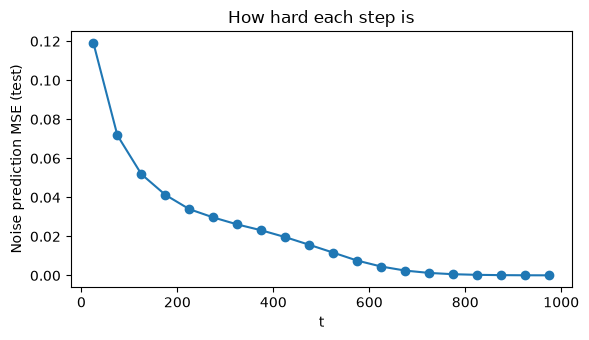

In [18]:
@torch.no_grad()
def loss_by_timestep(model, schedule=schedule, num_bins=20, num_images=2000):
    model.eval()
    images = test_images[:num_images]
    edges = np.linspace(0, schedule["num_timesteps"], num_bins + 1).astype(int)
    centers, losses = [], []
    for low, high in zip(edges[:-1], edges[1:]):
        t = torch.randint(low, high, (len(images),), device=device)
        noise = torch.randn_like(images)
        predicted_noise = model(q_sample(images, t, noise=noise, schedule=schedule), t)
        centers.append((low + high) / 2)
        losses.append(F.mse_loss(predicted_noise, noise).item())
    return centers, losses


seed_everything()
centers, losses = loss_by_timestep(denoiser)
plt.figure(figsize=(6, 3.5))
plt.plot(centers, losses, marker="o")
plt.xlabel("t")
plt.ylabel("Noise prediction MSE (test)")
plt.title("How hard each step is")
plt.tight_layout()
plt.show()

## 13. Generate New Digits

Pure Gaussian noise in, 1000 reverse steps, digits out.

64 digits in 4.2 s (1000 network passes)


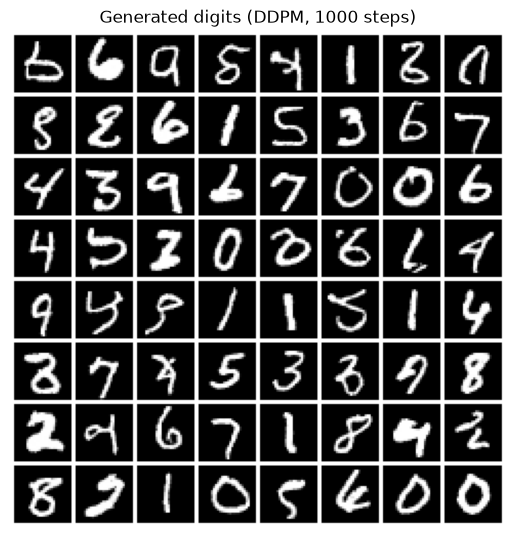

In [19]:
seed_everything(1234)
start = time.perf_counter()
samples = sample(denoiser, 64).cpu()
print(f"64 digits in {time.perf_counter() - start:.1f} s ({num_timesteps} network passes)")
show_image_grid(samples, title="Generated digits (DDPM, 1000 steps)")

### What the network sees at each step

At every step we can also ask where the network thinks it is going. Solving the jump formula for $x_0$ with the predicted noise gives its current guess of the final image:

$$\hat{x}_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t, t)}{\sqrt{\bar\alpha_t}}$$

Top row of each pair: the image $x_t$ along the way. Bottom row: the guess $\hat{x}_0$ at that moment.

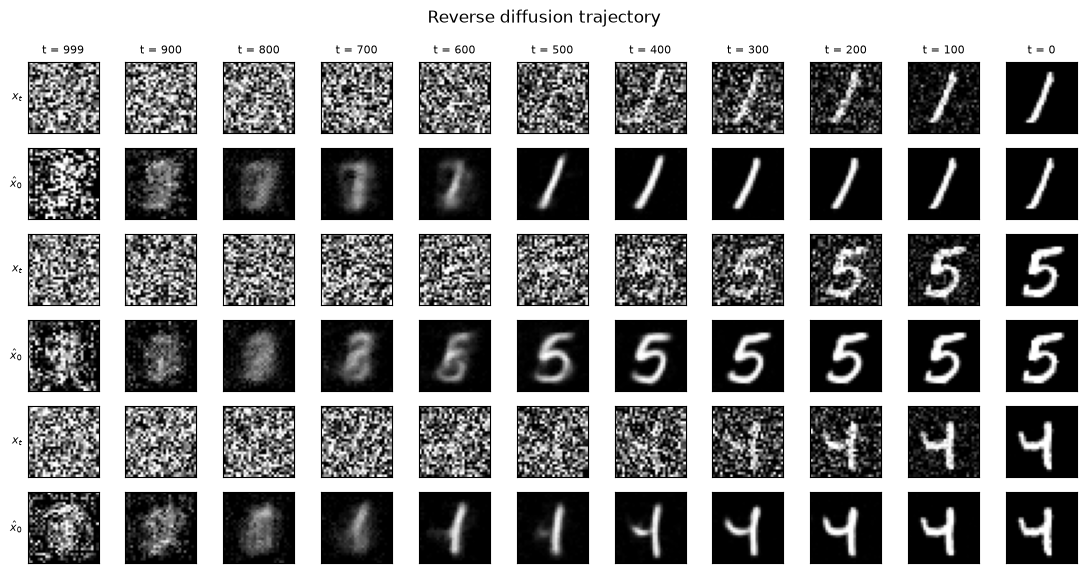

In [20]:
def predict_x0(x_t, t, predicted_noise, schedule=schedule):
    alpha_bar_t = extract(schedule["alpha_bars"], t, x_t.shape)
    return (x_t - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise) / torch.sqrt(alpha_bar_t)


@torch.no_grad()
def sampling_trajectory(model, num_images=3, snapshot_timesteps=(999, 900, 800, 700, 600, 500, 400, 300, 200, 100, 0)):
    model.eval()
    x = torch.randn(num_images, image_channels, image_size, image_size, device=device)
    noisy, guesses = [], []
    for timestep in reversed(range(num_timesteps)):
        if timestep in snapshot_timesteps:
            t = torch.full((num_images,), timestep, device=device, dtype=torch.long)
            noisy.append(x.clone())
            guesses.append(predict_x0(x, t, model(x, t)).clamp(-1, 1))
        x = p_sample(model, x, timestep)
    return torch.stack(noisy, 1), torch.stack(guesses, 1)   # (num_images, num_snapshots, 1, 28, 28)


seed_everything(7)
snapshot_timesteps = (999, 900, 800, 700, 600, 500, 400, 300, 200, 100, 0)
noisy, guesses = sampling_trajectory(denoiser, snapshot_timesteps=snapshot_timesteps)
rows, row_titles = [], []
for i in range(len(noisy)):
    rows += [noisy[i], guesses[i]]
    row_titles += ["$x_t$", r"$\hat{x}_0$"]
show_rows(rows, row_titles=row_titles, column_titles=[f"t = {t}" for t in snapshot_timesteps],
          title="Reverse diffusion trajectory")

## 14. The Fresh Noise of Each Step

Three ways to go back from **the same** starting noise $x_T$:

- DDPM, as above, twice (each run draws different fresh noise in each step).
- Only the mean of each step, without fresh noise (`add_noise=False`).

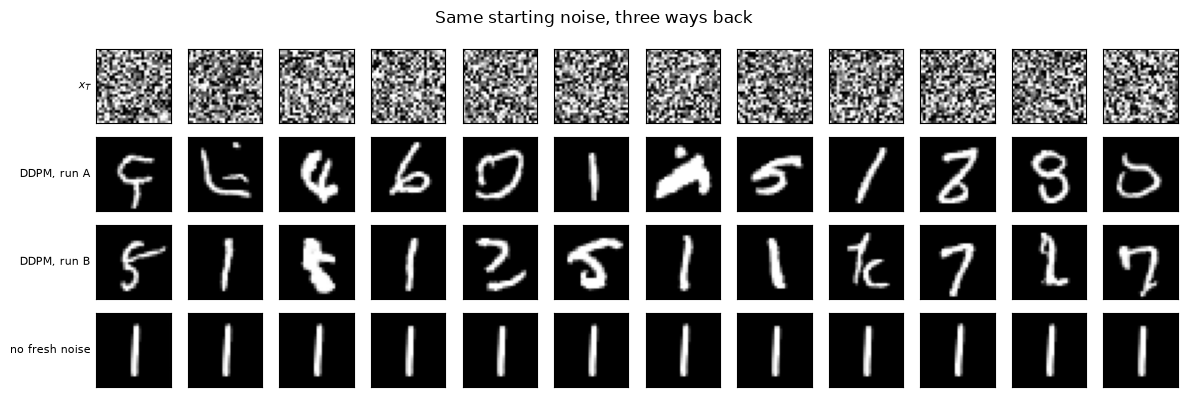

In [21]:
seed_everything(2024)
x_T = torch.randn(12, image_channels, image_size, image_size, device=device)
seed_everything(1)
run_a = sample(denoiser, x_T=x_T)
seed_everything(2)
run_b = sample(denoiser, x_T=x_T)
no_fresh_noise = sample(denoiser, x_T=x_T, add_noise=False)
show_rows([x_T, run_a, run_b, no_fresh_noise],
          row_titles=["$x_T$", "DDPM, run A", "DDPM, run B", "no fresh noise"],
          title="Same starting noise, three ways back")

## 15. Faster Sampling: DDIM

DDPM needs one network pass per step: 1000 passes per image. DDIM (Song et al., 2020) uses the same trained network (no retraining) but takes big deterministic jumps along a subset of the steps. At each step it uses $\hat{x}_0$ and the predicted noise to jump directly to an earlier step $s < t$:

$$x_s = \sqrt{\bar\alpha_s}\,\hat{x}_0 + \sqrt{1-\bar\alpha_s}\,\epsilon_\theta(x_t, t)$$

It adds no fresh noise, so the same $x_T$ always gives the same image. As usual for pixel-space models, we clip $\hat{x}_0$ to $[-1, 1]$ at each step and recompute the noise from it.

  DDPM, 1000 steps:  4.20 s for 64 digits
   DDIM, 100 steps:  0.43 s for 64 digits
    DDIM, 20 steps:  0.08 s for 64 digits
     DDIM, 5 steps:  0.02 s for 64 digits


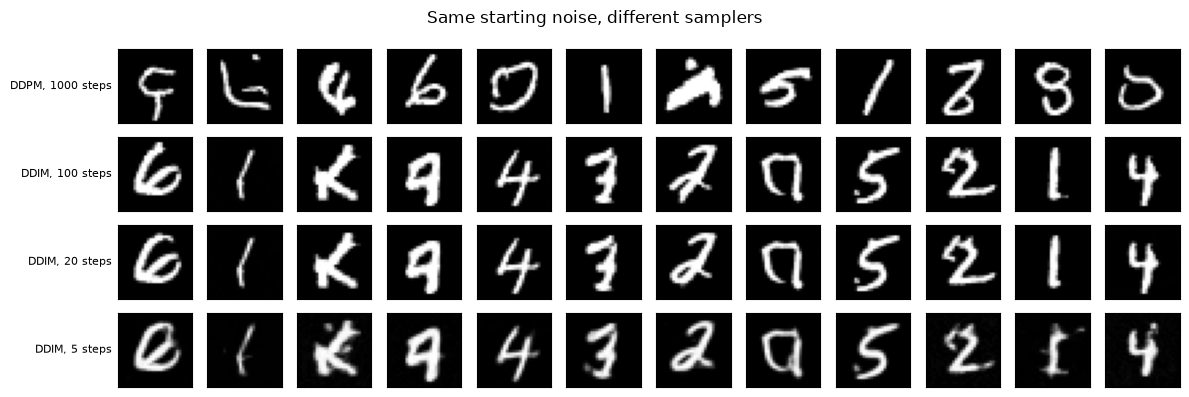

In [22]:
@torch.no_grad()
def ddim_sample(model, num_samples=64, num_steps=50, x_T=None, schedule=schedule):
    """Deterministic DDIM sampling with `num_steps` of the T steps."""
    model.eval()
    if x_T is None:
        x_T = torch.randn(num_samples, image_channels, image_size, image_size, device=device)
    x = x_T.clone()
    timesteps = torch.linspace(schedule["num_timesteps"] - 1, 0, num_steps).round().long().tolist()
    for i, timestep in enumerate(timesteps):
        t = torch.full((x.size(0),), timestep, device=device, dtype=torch.long)
        predicted_noise = model(x, t)
        x0_guess = predict_x0(x, t, predicted_noise, schedule).clamp(-1, 1)   # an image can't leave [-1, 1]
        alpha_bar_t = extract(schedule["alpha_bars"], t, x.shape)
        predicted_noise = (x - torch.sqrt(alpha_bar_t) * x0_guess) / torch.sqrt(1.0 - alpha_bar_t)  # consistent with it
        if i + 1 < len(timesteps):
            alpha_bar_next = schedule["alpha_bars"][timesteps[i + 1]]
        else:
            alpha_bar_next = torch.tensor(1.0, device=device)   # the last jump lands on x_0
        x = torch.sqrt(alpha_bar_next) * x0_guess + torch.sqrt(1.0 - alpha_bar_next) * predicted_noise
    return x.clamp(-1, 1)


seed_everything(2024)
x_T = torch.randn(64, image_channels, image_size, image_size, device=device)
rows, row_titles = [], []
for name, sampler in [("DDPM, 1000 steps", lambda: sample(denoiser, x_T=x_T)),
                      ("DDIM, 100 steps", lambda: ddim_sample(denoiser, num_steps=100, x_T=x_T)),
                      ("DDIM, 20 steps", lambda: ddim_sample(denoiser, num_steps=20, x_T=x_T)),
                      ("DDIM, 5 steps", lambda: ddim_sample(denoiser, num_steps=5, x_T=x_T))]:
    seed_everything(1)
    start = time.perf_counter()
    images = sampler().cpu()
    print(f"{name:>18}: {time.perf_counter() - start:5.2f} s for 64 digits")
    rows.append(images[:12])
    row_titles.append(name)
show_rows(rows, row_titles=row_titles, title="Same starting noise, different samplers")

## 16. Starting from a Real Image

Generation starts from pure noise, but the reverse process can start anywhere. We take real test digits, add the noise of step $t$ in one jump, and run the reverse process from there. The later the starting step, the more of the image the model has to make up. This is what the "strength" of image-to-image means in Stable Diffusion (see `stable_diffusion.ipynb`).

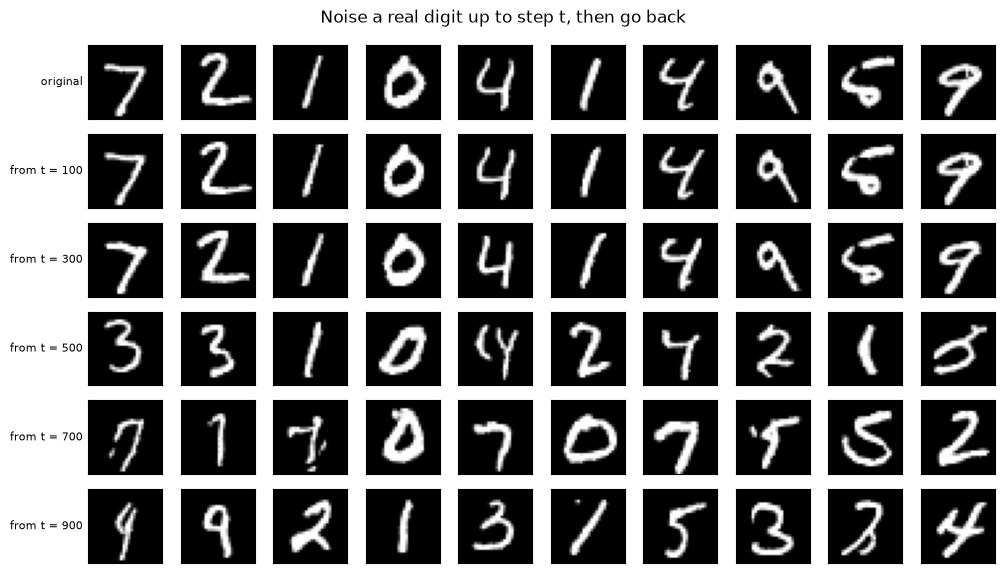

In [23]:
@torch.no_grad()
def denoise_from(model, images, start_timestep, schedule=schedule):
    model.eval()
    t = torch.full((images.size(0),), start_timestep, device=device, dtype=torch.long)
    x = q_sample(images, t, schedule=schedule)
    for timestep in reversed(range(start_timestep + 1)):
        x = p_sample(model, x, timestep, schedule=schedule)
    return x.clamp(-1, 1)


seed_everything(3)
originals = test_images[:10]
start_timesteps = [100, 300, 500, 700, 900]
show_rows([originals] + [denoise_from(denoiser, originals, t) for t in start_timesteps],
          row_titles=["original"] + [f"from t = {t}" for t in start_timesteps],
          title="Noise a real digit up to step t, then go back")

## 17. Choosing the Digit: Classifier-Free Guidance

So far we cannot choose which digit comes out. To steer generation we give the network a condition $c$, here the digit label (in Stable Diffusion, the text of the prompt): $\epsilon_\theta(x_t, t, c)$. The label goes in through an embedding that is added to the time embedding.

**Classifier-free guidance** (Ho and Salimans, 2022) trains the same network with and without the condition: during training, 10 % of the labels are replaced by a "no label" token. When sampling, we make two predictions and push away from the unconditional one:

$$\tilde\epsilon = \epsilon_\theta(x_t, t, \varnothing) + w\,\big(\epsilon_\theta(x_t, t, c) - \epsilon_\theta(x_t, t, \varnothing)\big)$$

With $w = 0$ the label is ignored; with $w = 1$ it is plain conditioning; with $w > 1$ the condition is exaggerated. In Stable Diffusion, $w$ is the `guidance_scale`.

In [24]:
num_classes = 10
p_uncond = 0.1


class ConditionalUNet(DenoisingUNet):
    """The same U-Net plus a label embedding. Label `num_classes` (10) means "no label"."""

    def __init__(self, num_classes=10, **kwargs):
        super().__init__(**kwargs)
        self.null_label = num_classes
        self.label_embedding = nn.Embedding(num_classes + 1, kwargs["time_dim"])

    def forward(self, x, timesteps, labels):
        return super().forward(x, timesteps, extra_embedding=self.label_embedding(labels))


def conditional_diffusion_loss(model, images, labels):
    drop = torch.rand(labels.shape, device=device) < p_uncond
    labels = torch.where(drop, torch.full_like(labels, model.null_label), labels)  # sometimes, no label
    t = torch.randint(0, num_timesteps, (images.size(0),), device=device)
    noise = torch.randn_like(images)
    predicted_noise = model(q_sample(images, t, noise=noise), t, labels)
    return F.mse_loss(predicted_noise, noise)


class Guided(nn.Module):
    """Wraps a conditional model so it predicts the guided noise for fixed labels. Works with sample() and ddim_sample()."""

    def __init__(self, model, labels, guidance_scale):
        super().__init__()
        self.model, self.labels, self.guidance_scale = model, labels, guidance_scale

    def forward(self, x, timesteps):
        no_labels = torch.full_like(self.labels, self.model.null_label)
        noise_cond, noise_uncond = self.model(
            torch.cat([x, x]), torch.cat([timesteps, timesteps]), torch.cat([self.labels, no_labels])
        ).chunk(2)
        return noise_uncond + self.guidance_scale * (noise_cond - noise_uncond)

Epoch 001/030 | train loss: 0.0742 | test loss: 0.0390 | 15 s
Epoch 002/030 | train loss: 0.0358 | test loss: 0.0323 | 15 s
Epoch 003/030 | train loss: 0.0303 | test loss: 0.0284 | 15 s
Epoch 004/030 | train loss: 0.0280 | test loss: 0.0266 | 15 s
Epoch 005/030 | train loss: 0.0265 | test loss: 0.0253 | 15 s


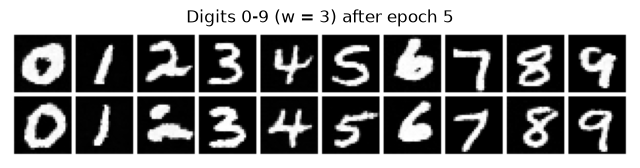

Epoch 006/030 | train loss: 0.0258 | test loss: 0.0259 | 15 s
Epoch 007/030 | train loss: 0.0252 | test loss: 0.0245 | 15 s
Epoch 008/030 | train loss: 0.0245 | test loss: 0.0242 | 15 s
Epoch 009/030 | train loss: 0.0244 | test loss: 0.0246 | 15 s
Epoch 010/030 | train loss: 0.0238 | test loss: 0.0233 | 15 s


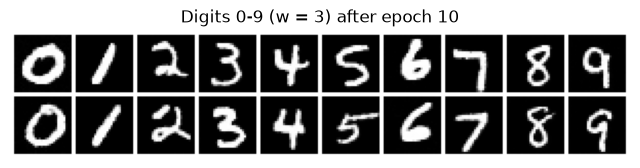

Epoch 011/030 | train loss: 0.0236 | test loss: 0.0245 | 15 s
Epoch 012/030 | train loss: 0.0234 | test loss: 0.0229 | 15 s
Epoch 013/030 | train loss: 0.0229 | test loss: 0.0229 | 15 s
Epoch 014/030 | train loss: 0.0231 | test loss: 0.0235 | 15 s
Epoch 015/030 | train loss: 0.0227 | test loss: 0.0224 | 15 s


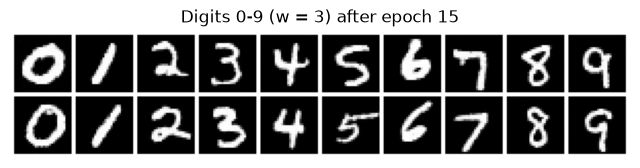

Epoch 016/030 | train loss: 0.0227 | test loss: 0.0235 | 15 s
Epoch 017/030 | train loss: 0.0225 | test loss: 0.0223 | 15 s
Epoch 018/030 | train loss: 0.0222 | test loss: 0.0227 | 15 s
Epoch 019/030 | train loss: 0.0223 | test loss: 0.0229 | 15 s
Epoch 020/030 | train loss: 0.0220 | test loss: 0.0220 | 15 s


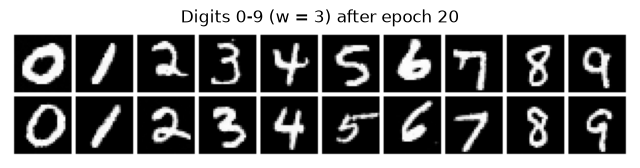

Epoch 021/030 | train loss: 0.0220 | test loss: 0.0232 | 15 s
Epoch 022/030 | train loss: 0.0219 | test loss: 0.0221 | 15 s
Epoch 023/030 | train loss: 0.0215 | test loss: 0.0227 | 15 s
Epoch 024/030 | train loss: 0.0217 | test loss: 0.0230 | 15 s
Epoch 025/030 | train loss: 0.0214 | test loss: 0.0221 | 15 s


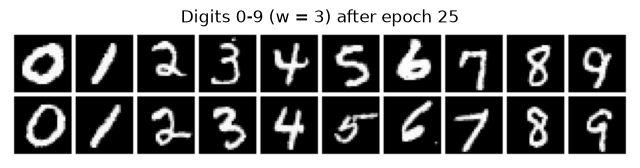

Epoch 026/030 | train loss: 0.0214 | test loss: 0.0233 | 15 s
Epoch 027/030 | train loss: 0.0212 | test loss: 0.0222 | 15 s
Epoch 028/030 | train loss: 0.0209 | test loss: 0.0228 | 15 s
Epoch 029/030 | train loss: 0.0211 | test loss: 0.0230 | 15 s
Epoch 030/030 | train loss: 0.0208 | test loss: 0.0224 | 15 s


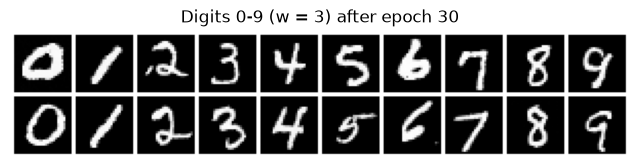

In [25]:
conditional_denoiser = ConditionalUNet(
    num_classes=num_classes,
    image_channels=image_channels,
    base_channels=base_channels,
    time_dim=time_embedding_dim,
    num_timesteps=num_timesteps,
).to(device)
digit_labels = torch.arange(10, device=device).repeat(2)   # 0..9, twice


def show_conditional_samples(epoch):
    seed_everything(0)
    images = sample(Guided(conditional_denoiser, digit_labels, guidance_scale=3.0), num_samples=len(digit_labels))
    show_image_grid(images, title=f"Digits 0-9 (w = 3) after epoch {epoch}", nrow=10)


conditional_history = train(conditional_denoiser, conditional_diffusion_loss, "ddpm_conditional",
                            show_samples=show_conditional_samples)

The same starting noise for every row; each column asks for a digit, 0 to 9, twice.

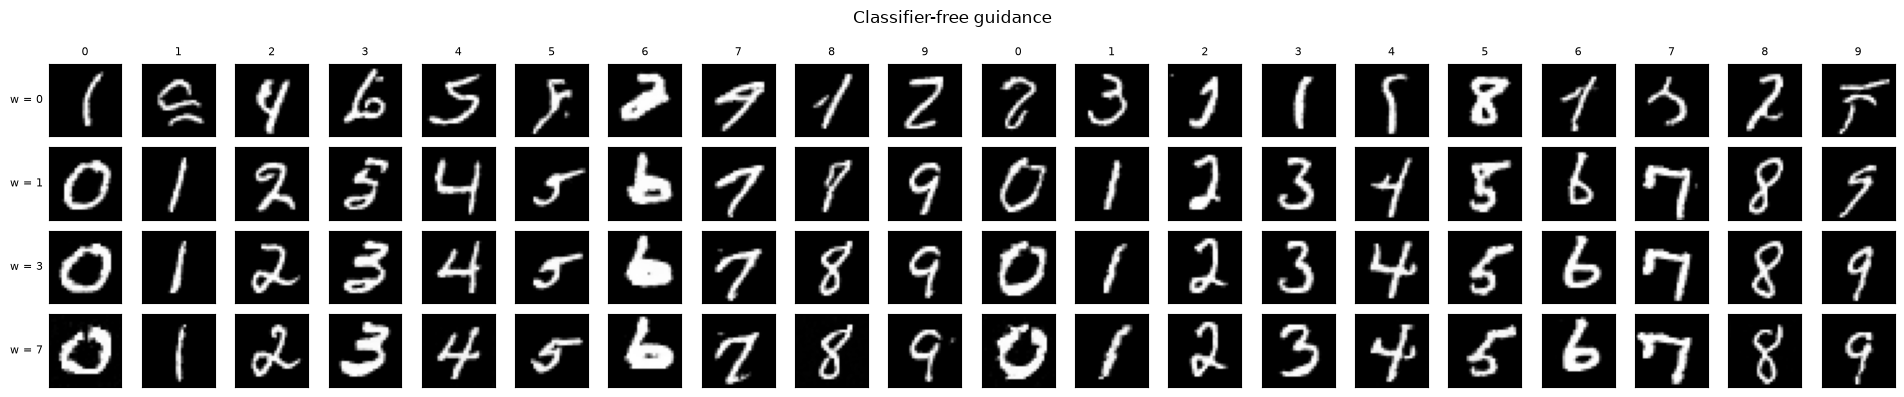

In [26]:
seed_everything(5)
x_T = torch.randn(len(digit_labels), image_channels, image_size, image_size, device=device)
guidance_scales = [0.0, 1.0, 3.0, 7.0]
rows = []
for w in guidance_scales:
    seed_everything(1)
    rows.append(sample(Guided(conditional_denoiser, digit_labels, guidance_scale=w), x_T=x_T))
show_rows(rows, row_titles=[f"w = {w:g}" for w in guidance_scales],
          column_titles=[str(d) for d in digit_labels.tolist()], title="Classifier-free guidance")

## 18. When the Scheduler Does Not Reach Noise

The scheduler and the number of steps go together. The $\beta$ of the DDPM paper were chosen for $T = 1000$. Let's keep the same $\beta$ (from $10^{-4}$ to $0.02$) but use only $T = 100$ steps, which looks like a harmless way to train and sample ten times faster.

With 100 steps, at the last step the image weighs 0.603 and the noise 0.798


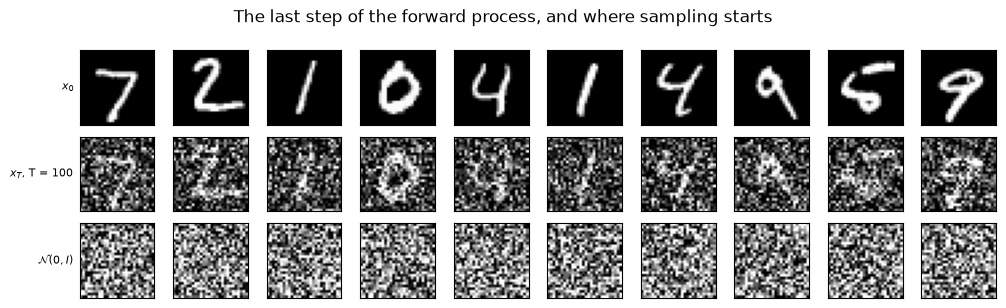

In [27]:
short_schedule = make_schedule(linear_betas(100, beta_start, beta_end))
alpha_bar_T = short_schedule["alpha_bars"][-1]
print(f"With 100 steps, at the last step the image weighs {alpha_bar_T.sqrt():.3f} and the noise {(1 - alpha_bar_T).sqrt():.3f}")

seed_everything()
x_T_short = q_sample(test_images[:10], torch.full((10,), 99, device=device), schedule=short_schedule)
show_rows([test_images[:10], x_T_short, torch.randn_like(x_T_short)],
          row_titles=["$x_0$", "$x_T$, T = 100", r"$\mathcal{N}(0, I)$"],
          title="The last step of the forward process, and where sampling starts")

The last step of the forward process still contains the digit, but sampling starts from $\mathcal{N}(0, I)$, something the network never saw during training. Let's train the same U-Net with this schedule (set `RUN_SCHEDULE_PITFALL = False` to skip it).

Epoch 001/020 | train loss: 0.1395 | test loss: 0.0860 | 14 s
Epoch 002/020 | train loss: 0.0771 | test loss: 0.0705 | 15 s
Epoch 003/020 | train loss: 0.0678 | test loss: 0.0636 | 15 s
Epoch 004/020 | train loss: 0.0635 | test loss: 0.0621 | 15 s
Epoch 005/020 | train loss: 0.0618 | test loss: 0.0613 | 15 s
Epoch 006/020 | train loss: 0.0603 | test loss: 0.0586 | 14 s
Epoch 007/020 | train loss: 0.0590 | test loss: 0.0579 | 14 s
Epoch 008/020 | train loss: 0.0582 | test loss: 0.0583 | 14 s
Epoch 009/020 | train loss: 0.0575 | test loss: 0.0572 | 15 s
Epoch 010/020 | train loss: 0.0571 | test loss: 0.0576 | 14 s
Epoch 011/020 | train loss: 0.0564 | test loss: 0.0566 | 15 s
Epoch 012/020 | train loss: 0.0563 | test loss: 0.0555 | 14 s
Epoch 013/020 | train loss: 0.0560 | test loss: 0.0558 | 15 s
Epoch 014/020 | train loss: 0.0556 | test loss: 0.0552 | 14 s
Epoch 015/020 | train loss: 0.0553 | test loss: 0.0559 | 15 s
Epoch 016/020 | train loss: 0.0549 | test loss: 0.0561 | 14 s
Epoch 01

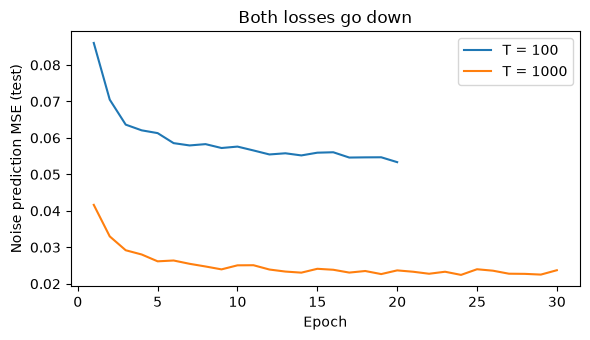

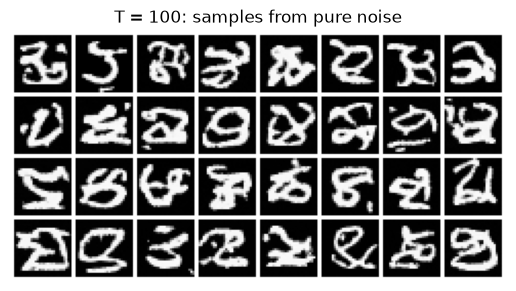

In [28]:
RUN_SCHEDULE_PITFALL = True

if RUN_SCHEDULE_PITFALL:
    short_denoiser = DenoisingUNet(
        image_channels=image_channels,
        base_channels=base_channels,
        time_dim=time_embedding_dim,
        num_timesteps=100,
    ).to(device)
    short_history = train(short_denoiser,
                          lambda model, images, labels: diffusion_loss(model, images, schedule=short_schedule),
                          "ddpm_100_steps", epochs=20)

    plt.figure(figsize=(6, 3.5))
    plt.plot([row["epoch"] for row in short_history], [row["test_loss"] for row in short_history], label="T = 100")
    plt.plot([row["epoch"] for row in history], [row["test_loss"] for row in history], label="T = 1000")
    plt.xlabel("Epoch")
    plt.ylabel("Noise prediction MSE (test)")
    plt.legend()
    plt.title("Both losses go down")
    plt.tight_layout()
    plt.show()

    seed_everything(1234)
    show_image_grid(sample(short_denoiser, 32, schedule=short_schedule), title="T = 100: samples from pure noise")

Now give the same network what it actually saw during training at the last step: the $x_T$ of real test digits.

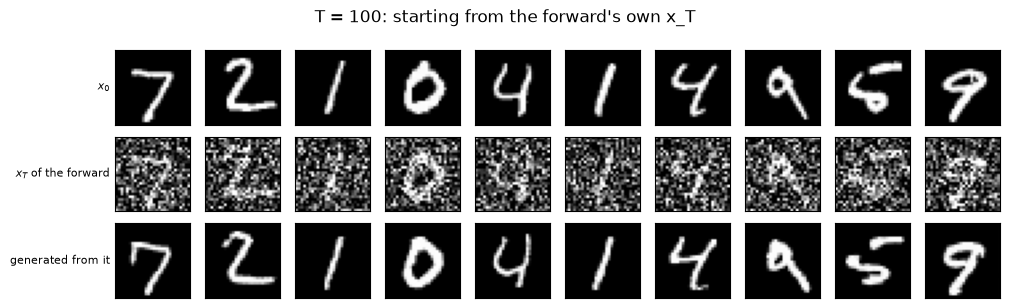

In [29]:
if RUN_SCHEDULE_PITFALL:
    seed_everything(1)
    show_rows([test_images[:10], x_T_short, sample(short_denoiser, x_T=x_T_short, schedule=short_schedule)],
              row_titles=["$x_0$", "$x_T$ of the forward", "generated from it"],
              title="T = 100: starting from the forward's own x_T")

Two ways to fix it: more steps, as in the rest of this notebook, or a scheduler that does reach noise in 100 steps, for example a larger `beta_end` (0.2) or the cosine schedule of Nichol and Dhariwal (2021). The plot compares how much of the image is left at each fraction of the process.

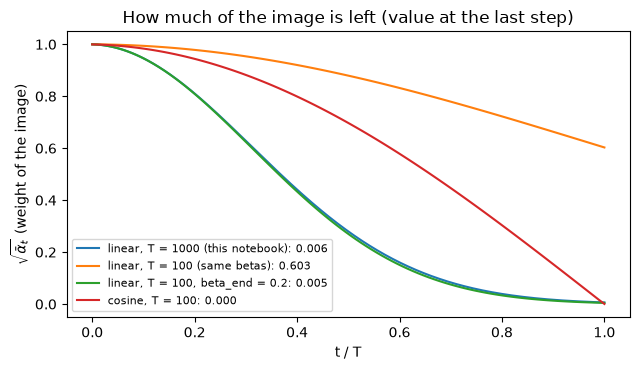

In [30]:
def cosine_betas(num_timesteps, s=0.008):
    steps = torch.arange(num_timesteps + 1, dtype=torch.float64) / num_timesteps
    alpha_bars = torch.cos((steps + s) / (1 + s) * math.pi / 2) ** 2
    alpha_bars = alpha_bars / alpha_bars[0]
    return (1 - alpha_bars[1:] / alpha_bars[:-1]).clamp(max=0.999).float()


schedules = {
    "linear, T = 1000 (this notebook)": schedule,
    "linear, T = 100 (same betas)": short_schedule,
    "linear, T = 100, beta_end = 0.2": make_schedule(linear_betas(100, beta_start, 0.2)),
    "cosine, T = 100": make_schedule(cosine_betas(100)),
}
plt.figure(figsize=(6.5, 3.8))
for name, s in schedules.items():
    alpha_bars = s["alpha_bars"].cpu().numpy()
    plt.plot(np.linspace(0, 1, len(alpha_bars)), np.sqrt(alpha_bars), label=f"{name}: {np.sqrt(alpha_bars[-1]):.3f}")
plt.xlabel("t / T")
plt.ylabel(r"$\sqrt{\bar\alpha_t}$ (weight of the image)")
plt.title("How much of the image is left (value at the last step)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 19. Things to Try

- Retrain the `T = 100` model with `beta_end = 0.2` or with `cosine_betas(100)`, and compare its samples with the ones above.
- Lower the number of DDIM steps until the digits break. How few are enough?
- Make the network predict $x_0$ instead of $\epsilon$ (change the target in `diffusion_loss` and the sampling formulas).
- Keep an exponential moving average (EMA) of the weights and sample with it, as the DDPM paper does.
- Train the conditional model on Fashion-MNIST and guide it with the clothing class.

## Troubleshooting

- **The loss goes down but the samples are scribbles:** check that the forward process reaches pure noise ($\sqrt{\bar\alpha_T}$ close to 0, section 18). Training longer does not fix it.
- **The samples look like noise:** train longer or increase `base_channels`.
- **Sampling is slow:** use `ddim_sample` with 50 steps or fewer.
- **Out of GPU memory:** lower `batch_size` or `base_channels`.